In [2]:
# 1. IMPORT LIBRARIES


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import ast
from pathlib import Path
sns.set_style('whitegrid')
from collections import Counter

warnings.filterwarnings('ignore', category=Warning)


In [3]:

# ============================================================
# 2. LOAD DATASETS
# ============================================================
DATA_DIR = Path.cwd().parent/ "data"

METADATA_FILE = DATA_DIR / "ptbxl_database.csv"
STATEMENTS_FILE = DATA_DIR / "scp_statements.csv"
df = pd.read_csv(METADATA_FILE)
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval) # string -> dict
scp = pd.read_csv(STATEMENTS_FILE, index_col=0)
# ============================================================
# CARDIOTRUSTAI - PTB-XL DATA EXPLORATION AND PREPROCESSING
# ============================================================


In [4]:
# ============================================================
# 3. BASIC DATA EXPLORATION
# ============================================================

print("Metadata Shape:", df.shape)
print("SCP Statements Shape:", scp.shape)

print("\nFirst Five ECG Records:")
display(df.head())

print("\nFirst Five SCP Statements:")
display(scp.head())

print("\nMetadata Columns:")
print(df.columns)

print("\nSCP Columns:")
print(scp.columns)

print("\nMetadata Information:")
df.info()

print("\nSCP Information:")
scp.info()

print("\nMetadata Statistical Summary:")
display(df.describe())

print("\nCategorical Statistical Summary:")
display(df.describe(include='object'))

print("\nSCP Statistical Summary:")
display(scp.describe(include='all'))

Metadata Shape: (21799, 28)
SCP Statements Shape: (71, 12)

First Five ECG Records:


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr



First Five SCP Statements:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7



Metadata Columns:
Index(['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse',
       'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr'],
      dtype='str')

SCP Columns:
Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='str')

Metadata Information:
<class 'pandas.DataFrame'>
RangeIndex: 21799 entries, 0 to 21798
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 

,ecg_id,patient_id,age,sex,height,weight,nurse,site,validated_by,strat_fold
count,21799.000000,21799.000000,21799.000000,21799.000000,6974.000000,9421.000000,20326.000000,21782.000000,12421.000000,21799.000000
mean,10926.658379,11250.156521,62.769301,0.479150,166.702323,70.995223,2.291745,1.544945,0.746075,5.503005
std,6302.393366,6235.026404,32.308813,0.499577,10.867321,15.878803,3.254033,4.172883,1.178003,2.874948
min,1.000000,302.000000,2.000000,0.000000,6.000000,5.000000,0.000000,0.000000,0.000000,1.000000
25%,5469.500000,5974.500000,50.000000,0.000000,160.000000,60.000000,0.000000,0.000000,0.000000,3.000000
50%,10926.000000,11419.000000,62.000000,0.000000,166.000000,70.000000,1.000000,1.000000,1.000000,6.000000
75%,16386.500000,16607.500000,72.000000,1.000000,174.000000,80.000000,3.000000,2.000000,1.000000,8.000000
max,21837.000000,21797.000000,300.000000,1.000000,209.000000,250.000000,11.000000,50.000000,11.000000,10.000000



Categorical Statistical Summary:


,device,recording_date,report,scp_codes,heart_axis,infarction_stadium1,infarction_stadium2,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,filename_lr,filename_hr
count,21799,21799,21799,21799,13331,5612,103,1598,3260,613,30,1949,291,21799,21799
unique,11,21795,9887,5298,8,6,3,317,124,103,14,128,4,21799,21799
top,CS100 3,1992-02-06 11:47:42,sinus rhythm. normal ecg.,"{'NORM': 100.0, 'SR': 0.0}",MID,unknown,Stadium III,", V6",", I-AVR,",alles,V6,1ES,"ja, pacemaker",records100/00000/00001_lr,records500/00000/00001_hr
freq,6140,2,1734,6142,7687,3430,65,221,953,140,8,405,285,1,1



SCP Statistical Summary:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
count,71,44.0,19.0,12.0,44,44,71,71,37.000000,23,13,13
unique,71,NaN,NaN,NaN,5,23,15,66,NaN,23,13,13
top,non-diagnostic T abnormalities,NaN,NaN,NaN,MI,IMI,Statements related to impulse formation (abnor...,in anterolateral leads,NaN,MDC_ECG_RHY_STHILOST,C71076,F-000B7
freq,1,NaN,NaN,NaN,14,6,10,2,NaN,1,1,1
mean,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,144.297297,NaN,NaN,NaN
std,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,119.739037,NaN,NaN,NaN
min,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,60.000000,NaN,NaN,NaN
50%,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,140.000000,NaN,NaN,NaN
75%,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,162.000000,NaN,NaN,NaN


In [5]:

# ============================================================
# 4. CHECK MISSING VALUES
# ============================================================

print("\nMissing Values Per Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# print("\nMissing Value Percentage:")

# missing_percentage = (df.isnull().sum() / len(df)) * 100

# print(missing_percentage.sort_values(ascending=False))

print("\nSCP Missing Values:")
print(scp.isnull().sum())

# plt.figure(figsize=(15, 6))

# sns.heatmap(df.isnull(), cbar=False)

# plt.title("Missing Values in PTB-XL Metadata")

# plt.show()




Missing Values Per Column:
ecg_id                              0
patient_id                          0
age                                 0
sex                                 0
height                          14825
weight                          12378
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold            

In [6]:
# ============================================================
# 5. CHECK DUPLICATE RECORDS
# ============================================================

print("\nDuplicate ECG IDs:")
print(df['ecg_id'].duplicated().sum())

print("\nDuplicate Patient IDs:")
print(df['patient_id'].duplicated().sum())

print("\nUnique Patients:")
print(df['patient_id'].nunique())

print("\nDuplicate ECG Records:")
display(df[df['ecg_id'].duplicated(keep=False)])


Duplicate ECG IDs:
0

Duplicate Patient IDs:
2930

Unique Patients:
18869

Duplicate ECG Records:


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr


In [7]:
# ============================================================
# 6. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()

print("\nNumerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'validated_by', 'strat_fold']

Categorical Columns:
['device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'filename_lr', 'filename_hr']


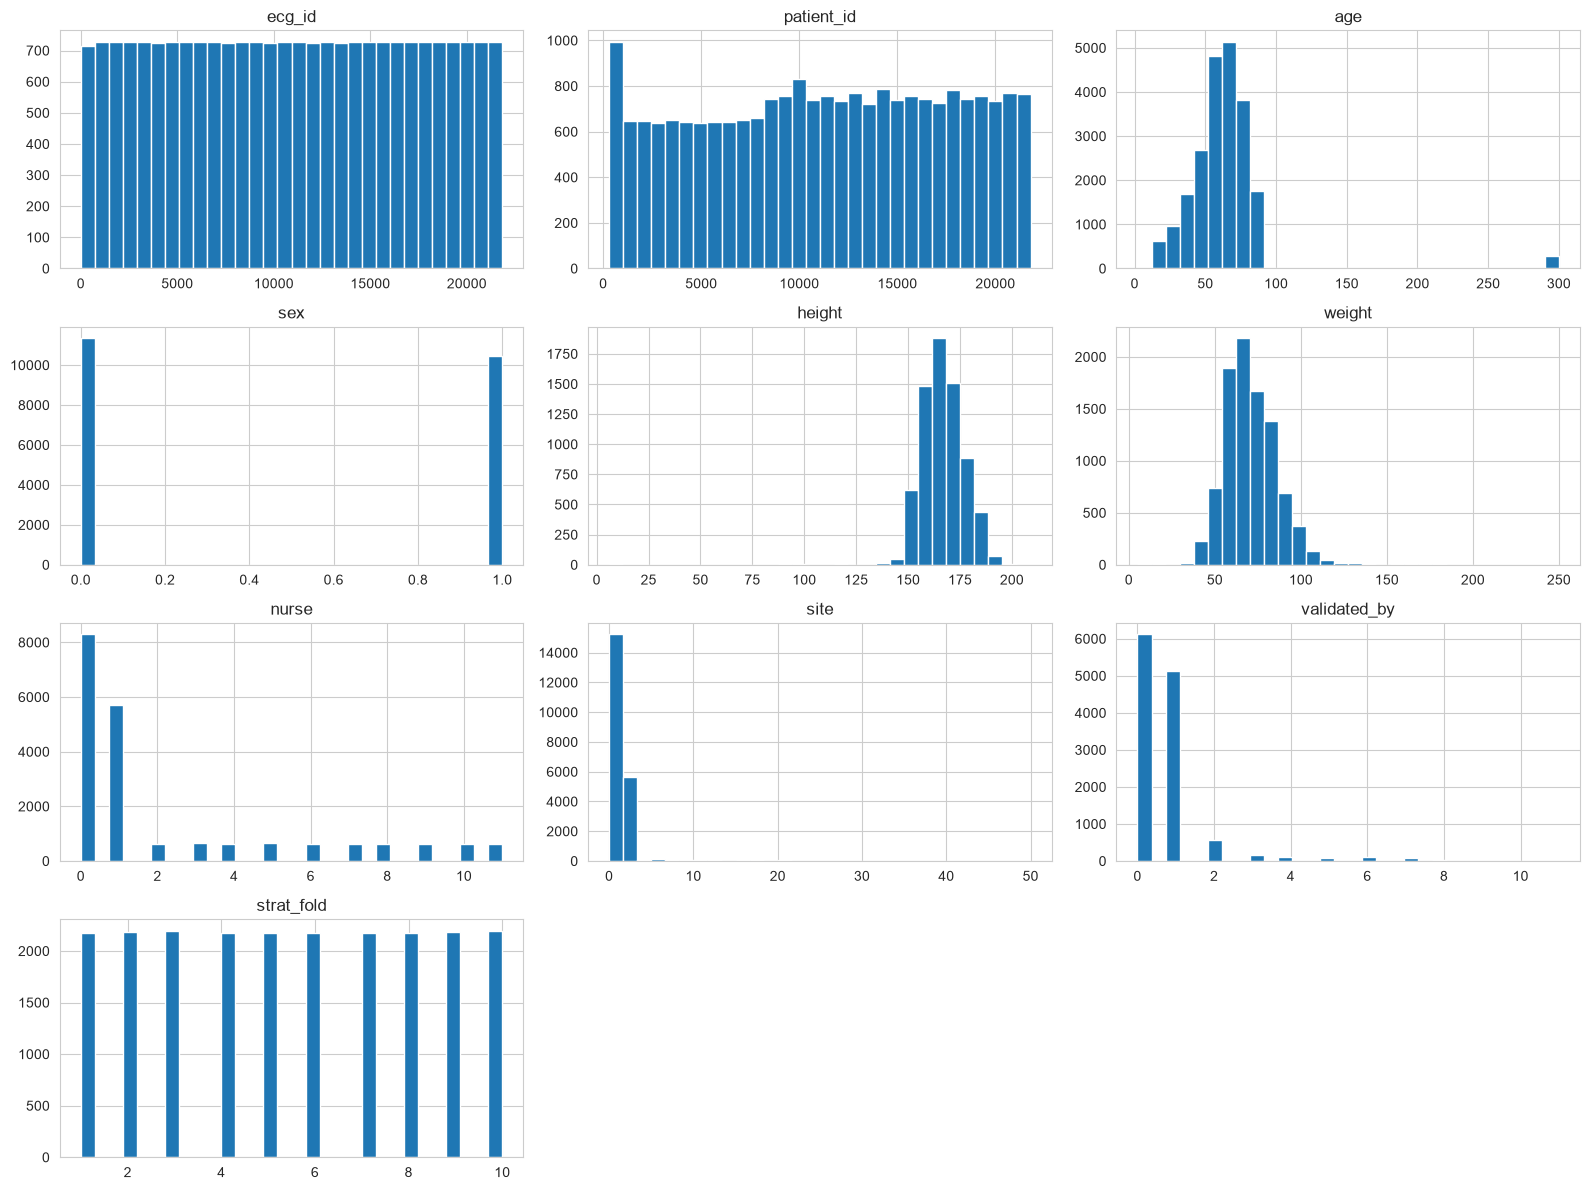

In [8]:

# ============================================================
# 7. NUMERICAL FEATURE DISTRIBUTION
# ============================================================

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()

plt.show()


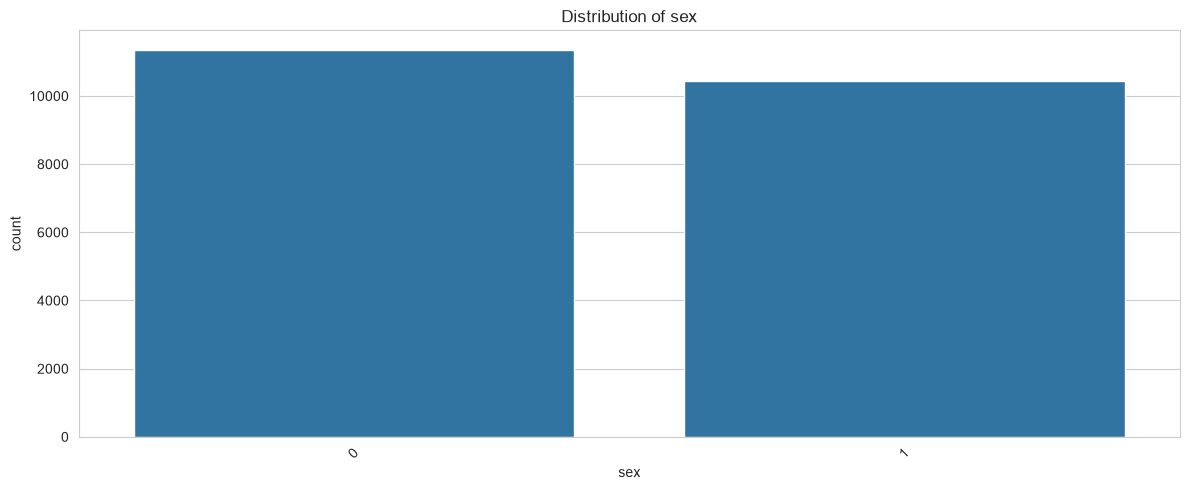

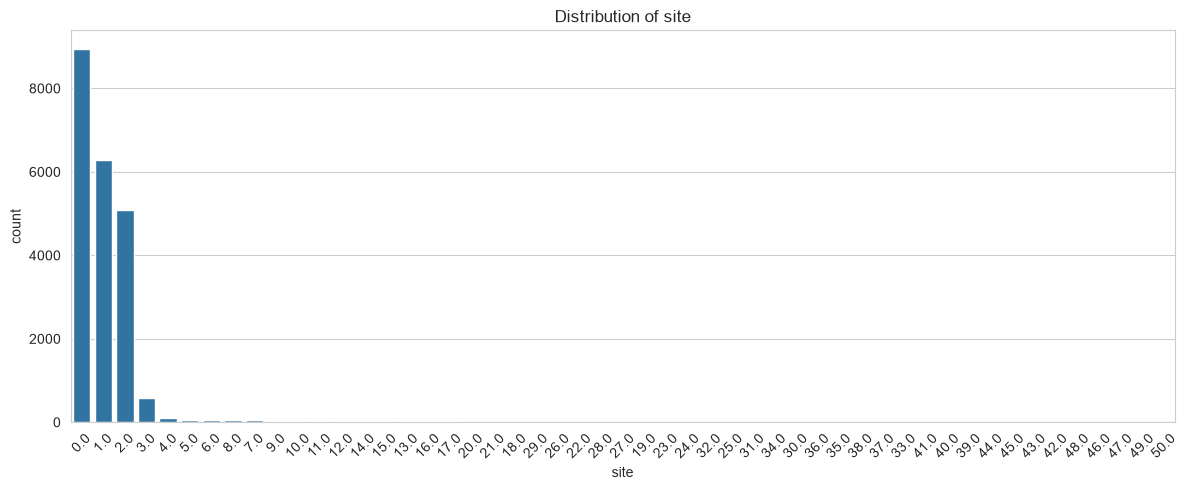

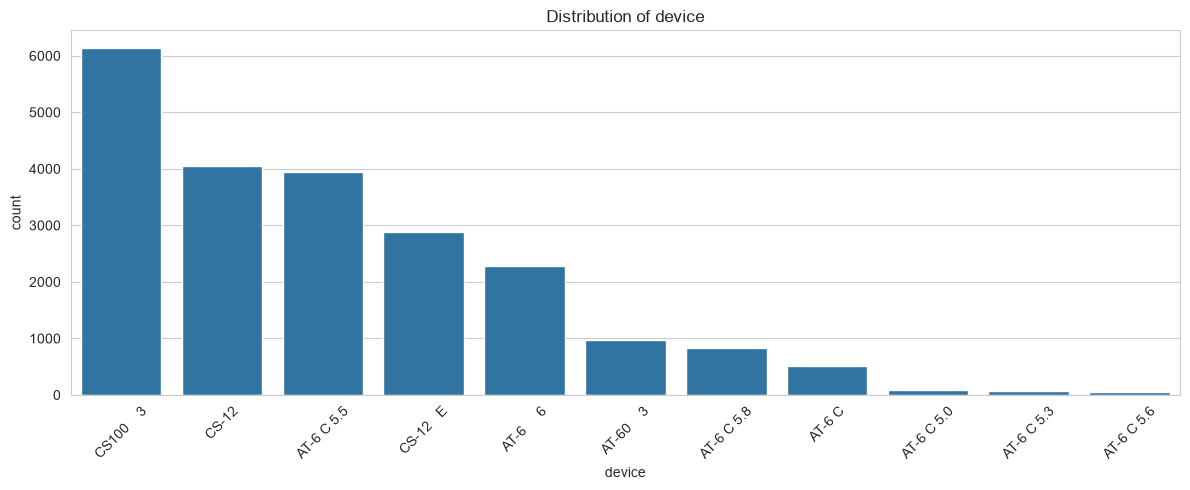

In [9]:

# ============================================================
# 8. CATEGORICAL FEATURE DISTRIBUTION
# ============================================================

for col in ['sex', 'site', 'device']:

    if col in df.columns:

        plt.figure(figsize=(12, 5))

        sns.countplot(
            data=df,
            x=col,
            order=df[col].value_counts().index
        )

        plt.title(f"Distribution of {col}")

        plt.xticks(rotation=45)

        plt.tight_layout()

        plt.show()

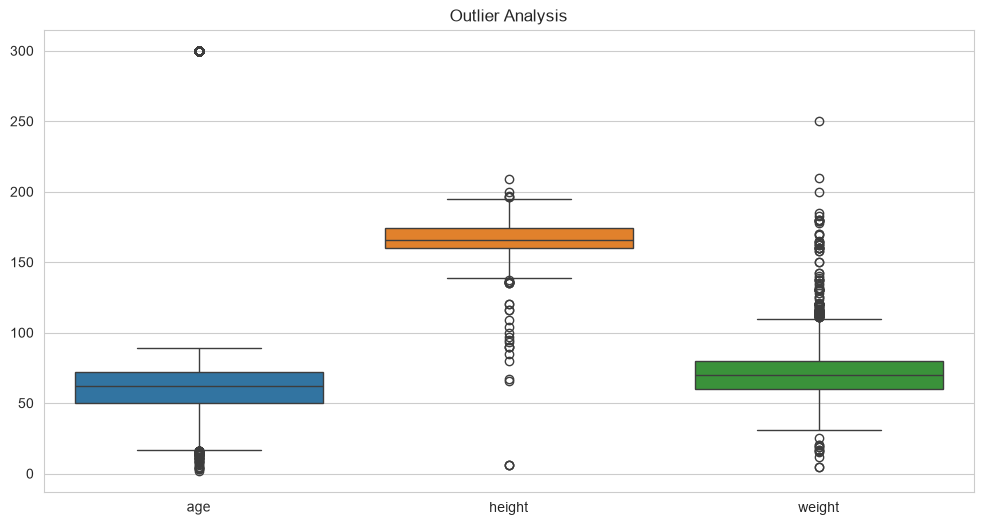

In [10]:

# ============================================================
# 9. OUTLIER ANALYSIS
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[['age', 'height', 'weight']]
)

plt.title("Outlier Analysis")

plt.show()


In [11]:
# ============================================================
# 10. CREATE A CLEANED DATAFRAME
# ============================================================

df_clean = df.copy()
df_clean.isnull().sum()

ecg_id                              0
patient_id                          0
age                                 0
sex                                 0
height                          14825
weight                          12378
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold                          0
filename_lr 

In [12]:

# ============================================================
# 11. CLEAN AGE
# ============================================================

print("\nAge Statistics Before Cleaning:")
print(df_clean['age'].describe())

print("\nInvalid Age Values:")

display(df_clean.loc[df_clean['age'] > 100, ['ecg_id', 'age']])

df_clean.loc[
    (df_clean['age'] < 0) | (df_clean['age'] > 100),
    'age'
] = np.nan

print("\nAge Statistics After Cleaning:")
print(df_clean['age'].describe())



Age Statistics Before Cleaning:
count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64

Invalid Age Values:


,ecg_id,age
107,108,300.0
247,255,300.0
248,256,300.0
271,279,300.0
274,282,300.0
...,...,...
20826,20865,300.0
20839,20878,300.0
21082,21121,300.0
21101,21140,300.0



Age Statistics After Cleaning:
count    21506.000000
mean        59.537245
std         16.758773
min          2.000000
25%         50.000000
50%         61.000000
75%         72.000000
max         89.000000
Name: age, dtype: float64


In [13]:
# ============================================================
# 12. CLEAN HEIGHT
# ============================================================
# Before cleaning

print("\nHeight Statistics Before Cleaning:")
print(df_clean['height'].describe())

df_clean.loc[
    (df_clean['height'] < 100) |
    (df_clean['height'] > 220),
    'height'
] = np.nan

print("\nHeight Statistics After Cleaning:")
print(df_clean['height'].describe())
# After cleaning
print("Missing Height Values After Cleaning:")
print(df_clean['height'].isna().sum())


Height Statistics Before Cleaning:
count    6974.000000
mean      166.702323
std        10.867321
min         6.000000
25%       160.000000
50%       166.000000
75%       174.000000
max       209.000000
Name: height, dtype: float64

Height Statistics After Cleaning:
count    6961.000000
mean      166.888522
std         9.872968
min       100.000000
25%       160.000000
50%       166.000000
75%       174.000000
max       209.000000
Name: height, dtype: float64
Missing Height Values After Cleaning:
14838


In [14]:

# ============================================================
# 13. CLEAN WEIGHT
# ============================================================
print("Missing weight Values Before Cleaning:")
print(df_clean['weight'].isna().sum())
# print("\nWeight Statistics Before Cleaning:")
# print(df_clean['weight'].describe())

df_clean.loc[
    (df_clean['weight'] < 20) |
    (df_clean['weight'] > 200),
    'weight'
] = np.nan

print("\nWeight Statistics After Cleaning:")
print(df_clean['weight'].describe())
print("Missing weight Values After Cleaning:")
print(df_clean['weight'].isna().sum())

Missing weight Values Before Cleaning:
12378

Weight Statistics After Cleaning:
count    9410.000000
mean       71.016047
std        15.614955
min        20.000000
25%        60.000000
50%        70.000000
75%        80.000000
max       200.000000
Name: weight, dtype: float64
Missing weight Values After Cleaning:
12389


In [15]:
# ============================================================
# 14. CHECK CLEANED MISSING VALUES
# ============================================================

print("\nMissing Values After Cleaning:")

print(df_clean.isnull().sum())


Missing Values After Cleaning:
ecg_id                              0
patient_id                          0
age                               293
sex                                 0
height                          14838
weight                          12389
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold        

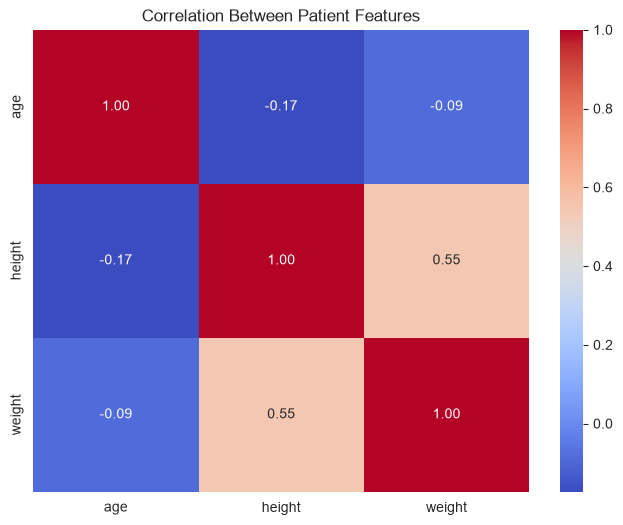

In [16]:
# ============================================================
# 15. CORRELATION ANALYSIS
# ============================================================

correlation_columns = [
    'age',
    'height',
    'weight'
]

correlation = df_clean[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Patient Features")

plt.show()

In [17]:

# ============================================================
# 16. PARSE SCP DIAGNOSTIC CODES
# ============================================================

def parse_scp_codes(value):

    if pd.isna(value):
        return {}

    try:

        result = ast.literal_eval(value)

        if isinstance(result, dict):
            return result

        return {}

    except (ValueError, SyntaxError):

        return {}


df_clean['scp_codes_dict'] = df_clean['scp_codes'].apply(
    parse_scp_codes
)

print("\nParsed SCP Codes:")

display(
    df_clean[['scp_codes', 'scp_codes_dict']].head()
)


Parsed SCP Codes:


,scp_codes,scp_codes_dict
0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",{}
1,"{'NORM': 80.0, 'SBRAD': 0.0}",{}
2,"{'NORM': 100.0, 'SR': 0.0}",{}
3,"{'NORM': 100.0, 'SR': 0.0}",{}
4,"{'NORM': 100.0, 'SR': 0.0}",{}


In [18]:

# ============================================================
# 17. EXPLORE SCP STATEMENTS
# ============================================================

print("\nSCP Statement Columns:")
print(scp.columns)

print("\nDiagnostic Statement Distribution:")

print(
    scp['diagnostic'].value_counts(dropna=False)
)

print("\nDiagnostic Class Distribution:")

print(
    scp['diagnostic_class'].value_counts(dropna=False)
)


SCP Statement Columns:
Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='str')

Diagnostic Statement Distribution:
diagnostic
1.0    44
NaN    27
Name: count, dtype: int64

Diagnostic Class Distribution:
diagnostic_class
NaN     27
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


In [19]:
print("Original SCP Codes:")

display(df_clean[['scp_codes']].head(10))

print("\nData Type:")
print(df_clean['scp_codes'].dtype)

print("\nFirst Value:")
print(repr(df_clean['scp_codes'].iloc[0]))

print("\nMissing Values:")
print(df_clean['scp_codes'].isna().sum())

Original SCP Codes:


,scp_codes
0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,"{'NORM': 100.0, 'SR': 0.0}"
3,"{'NORM': 100.0, 'SR': 0.0}"
4,"{'NORM': 100.0, 'SR': 0.0}"
5,"{'NORM': 100.0, 'SR': 0.0}"
6,"{'NORM': 100.0, 'SR': 0.0}"
7,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}"
8,"{'NORM': 100.0, 'SR': 0.0}"
9,"{'NORM': 100.0, 'SR': 0.0}"



Data Type:
object

First Value:
{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

Missing Values:
0


In [20]:
# ============================================================
# 16. PARSE SCP DIAGNOSTIC CODES
# ============================================================

def parse_scp_codes(value):

    if isinstance(value, dict):
        return value

    if pd.isna(value):
        return {}

    try:

        result = ast.literal_eval(value)

        if isinstance(result, dict):
            return result

        return {}

    except (ValueError, SyntaxError, TypeError):

        return {}


df_clean['scp_codes_dict'] = df_clean['scp_codes'].apply(
    parse_scp_codes
)

print("\nParsed SCP Codes:")

display(
    df_clean[['scp_codes', 'scp_codes_dict']].head(10)
)


Parsed SCP Codes:


,scp_codes,scp_codes_dict
0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}","{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,"{'NORM': 80.0, 'SBRAD': 0.0}","{'NORM': 80.0, 'SBRAD': 0.0}"
2,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
3,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
4,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
5,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
6,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
7,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}","{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}"
8,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
9,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"


In [21]:
# ============================================================
# 18. MAP SCP CODES TO DIAGNOSTIC CLASSES
# ============================================================

diagnostic_map = scp.loc[
    scp['diagnostic'] == 1,
    'diagnostic_class'
].to_dict()


def get_diagnostic_classes(codes):

    classes = set()

    for code in codes:

        diagnostic_class = diagnostic_map.get(code)

        if pd.notna(diagnostic_class):

            classes.add(diagnostic_class)

    return sorted(classes)


df_clean['diagnostic_classes'] = (
    df_clean['scp_codes_dict'].apply(get_diagnostic_classes)
)

display(
    df_clean[['scp_codes_dict', 'diagnostic_classes']].head(10)
)

,scp_codes_dict,diagnostic_classes
0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM]
1,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM]
2,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
3,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
4,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
5,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
6,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
7,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI]
8,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
9,"{'NORM': 100.0, 'SR': 0.0}",[NORM]



Diagnostic Class Counts:
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
dtype: int64


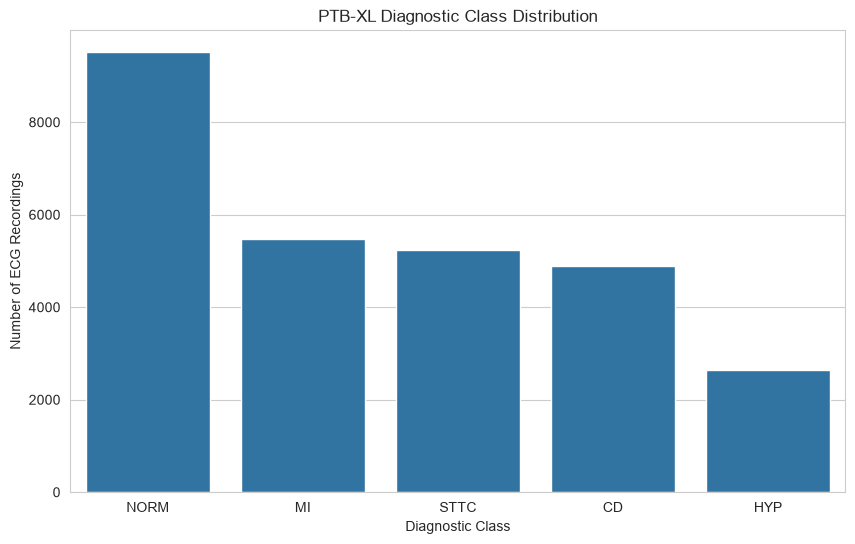

In [22]:
# ============================================================
# 19. COUNT DIAGNOSTIC CLASSES
# ============================================================

class_counts = Counter(
    label
    for labels in df_clean['diagnostic_classes']
    for label in labels
)

class_counts = pd.Series(class_counts).sort_values(
    ascending=False
)

print("\nDiagnostic Class Counts:")

print(class_counts)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("PTB-XL Diagnostic Class Distribution")

plt.xlabel("Diagnostic Class")

plt.ylabel("Number of ECG Recordings")

plt.show()

In [55]:
df_clean.isnull().sum()

ecg_id                              0
patient_id                          0
age                               293
sex                                 0
height                          14838
weight                          12389
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold                          0
filename_lr 


Binary Target Distribution:
abnormal_ecg
1.0    12319
0.0     9069
NaN      411
Name: count, dtype: int64


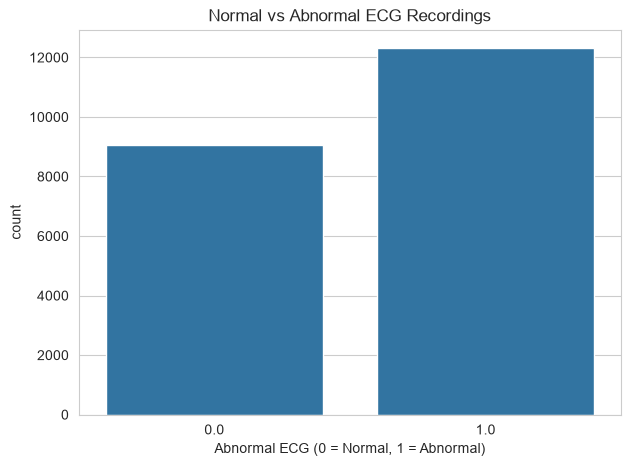

In [23]:
# ============================================================
# 20. CREATE BINARY CLASSIFICATION TARGET
# ============================================================

abnormal_classes = {
    'MI',
    'STTC',
    'CD',
    'HYP'
}


def create_binary_target(classes):

    if not classes:
        return np.nan

    return int(
        any(label in abnormal_classes for label in classes)
    )


df_clean['abnormal_ecg'] = (
    df_clean['diagnostic_classes'].apply(create_binary_target)
)

print("\nBinary Target Distribution:")

print(
    df_clean['abnormal_ecg'].value_counts(dropna=False)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='abnormal_ecg'
)

plt.title("Normal vs Abnormal ECG Recordings")

plt.xlabel("Abnormal ECG (0 = Normal, 1 = Abnormal)")

plt.show()


In [24]:
# ============================================================
# 21. PREPARE MODEL FEATURES
# ============================================================

feature_columns = [
    'age',
    'sex',
    'height',
    'weight'
]

df_model = df_clean.loc[
    df_clean['abnormal_ecg'].notna()
].copy()

X = df_model[feature_columns].copy()

y = df_model['abnormal_ecg'].astype(int)

print("\nFeature Shape:", X.shape)

print("\nTarget Shape:", y.shape)

print("\nTarget Distribution:")

print(y.value_counts())



Feature Shape: (21388, 4)

Target Shape: (21388,)

Target Distribution:
abnormal_ecg
1    12319
0     9069
Name: count, dtype: int64


In [25]:
df_model.head(10)

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,scp_codes_dict,diagnostic_classes,abnormal_ecg
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM],0.0
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM],0.0
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0
5,6,19005.0,18.0,1,NaN,58.0,2.0,0.0,CS-12 E,1984-11-28 13:32:13,...,NaN,NaN,NaN,NaN,4,records100/00000/00006_lr,records500/00000/00006_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0
6,7,16193.0,54.0,0,NaN,83.0,2.0,0.0,CS-12 E,1984-11-28 13:32:22,...,NaN,NaN,NaN,NaN,7,records100/00000/00007_lr,records500/00000/00007_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0
7,8,11275.0,48.0,0,NaN,95.0,2.0,0.0,CS-12 E,1984-12-01 14:49:52,...,NaN,NaN,NaN,NaN,9,records100/00000/00008_lr,records500/00000/00008_hr,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI],1.0
8,9,18792.0,55.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-12-08 09:44:43,...,NaN,NaN,NaN,NaN,10,records100/00000/00009_lr,records500/00000/00009_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0
9,10,9456.0,22.0,1,NaN,56.0,2.0,0.0,CS-12 E,1984-12-12 14:12:46,...,NaN,NaN,NaN,NaN,9,records100/00000/00010_lr,records500/00000/00010_hr,"{'NORM': 100.0, 'SR': 0.0}",[NORM],0.0


In [27]:

# ============================================================
# 22. SPLIT DATA USING OFFICIAL PTB-XL FOLDS
# ============================================================

train_df = df_model[
    df_model['strat_fold'].between(1, 8)
].copy()

val_df = df_model[
    df_model['strat_fold'] == 9
].copy()

test_df = df_model[
    df_model['strat_fold'] == 10
].copy()

print("\nTraining Shape:", train_df.shape)

print("Validation Shape:", val_df.shape)

print("Testing Shape:", test_df.shape)


Training Shape: (17084, 31)
Validation Shape: (2146, 31)
Testing Shape: (2158, 31)


In [28]:
# ============================================================
# 23. CHECK PATIENT DATA LEAKAGE
# ============================================================

train_patients = set(train_df['patient_id'])

val_patients = set(val_df['patient_id'])

test_patients = set(test_df['patient_id'])

print("\nTrain and Validation Overlap:")

print(len(train_patients & val_patients))

print("\nTrain and Test Overlap:")

print(len(train_patients & test_patients))

print("\nValidation and Test Overlap:")

print(len(val_patients & test_patients))


Train and Validation Overlap:
0

Train and Test Overlap:
0

Validation and Test Overlap:
0


In [30]:
# ============================================================
# 24. PREPARE TRAINING, VALIDATION AND TEST FEATURES
# ============================================================

X_train = train_df[feature_columns].copy()

X_val = val_df[feature_columns].copy()

X_test = test_df[feature_columns].copy()

y_train = train_df['abnormal_ecg'].astype(int)

y_val = val_df['abnormal_ecg'].astype(int)

y_test = test_df['abnormal_ecg'].astype(int)

In [31]:
# ============================================================
# 25. HANDLE MISSING VALUES
# ============================================================

from sklearn.impute import SimpleImputer

numerical_features = [
    'age',
    'height',
    'weight'
]

imputer = SimpleImputer(
    strategy='median'
)

X_train[numerical_features] = imputer.fit_transform(
    X_train[numerical_features]
)

X_val[numerical_features] = imputer.transform(
    X_val[numerical_features]
)

X_test[numerical_features] = imputer.transform(
    X_test[numerical_features]
)


In [32]:
# ============================================================
# 26. FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_val[numerical_features] = scaler.transform(
    X_val[numerical_features]
)

X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)


In [41]:
# ============================================================
# 27. FINAL DATA CHECK
# ============================================================

print("\nFinal Training Features:")

display(X_train.head())

print("\nFinal Validation Features:")

display(X_val.head())

print("\nFinal Testing Features:")

display(X_test.head())

print("\nFinal Dataset Shapes:")

print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("X_test:", X_test.shape)

print("y_train:", y_train.shape)

print("y_val:", y_val.shape)

print("y_test:", y_test.shape)

print("\nMissing Values in Training:")

print(X_train.isnull().sum())

print("\nMissing Values in Validation:")

print(X_val.isnull().sum())

print("\nMissing Values in Testing:")

print(X_test.isnull().sum())


Final Training Features:


,age,sex,height,weight
0,-0.197112,1,-0.049048,-0.716143
1,-2.430540,0,-0.049048,-0.030024
2,-1.344008,1,-0.049048,-0.128041
3,-2.128725,0,-0.049048,1.146181
4,-2.430540,1,-0.049048,-0.030024



Final Validation Features:


,age,sex,height,weight
7,-0.680016,0,-0.049048,2.420404
9,-2.249451,1,-0.049048,-1.402263
25,-0.197112,0,-0.049048,-0.030024
27,-0.197112,0,-0.049048,-0.030024
29,-2.068362,0,-0.049048,1.244198



Final Testing Features:


,age,sex,height,weight
8,-0.257475,0,-0.049048,-0.030024
37,-1.162919,0,-0.049048,0.166011
39,0.044339,0,-0.049048,1.440233
56,-2.008000,0,-0.049048,2.224369
58,-0.317838,0,-0.049048,-0.324075



Final Dataset Shapes:
X_train: (17084, 4)
X_val: (2146, 4)
X_test: (2158, 4)
y_train: (17084,)
y_val: (2146,)
y_test: (2158,)

Missing Values in Training:
age       0
sex       0
height    0
weight    0
dtype: int64

Missing Values in Validation:
age       0
sex       0
height    0
weight    0
dtype: int64

Missing Values in Testing:
age       0
sex       0
height    0
weight    0
dtype: int64


In [42]:
DATA_DIR = Path.cwd().parent / "data"

In [43]:

# ============================================================
# 1. LOCATE THE 100 ECG RECORDINGS
# ============================================================

ECG_DIR = DATA_DIR / "records100"

print("ECG Folder:", ECG_DIR)
print("Folder Exists:", ECG_DIR.exists())

# Find all ECG header files
header_files = sorted(ECG_DIR.rglob("*.hea"))

# Find all ECG signal files
signal_files = sorted(ECG_DIR.rglob("*.dat"))

print("\nNumber of ECG Header Files:", len(header_files))
print("Number of ECG Signal Files:", len(signal_files))

print("\nFirst 10 ECG Recordings:")

for file in header_files[:10]:
    print(file.relative_to(ECG_DIR))


ECG Folder: /Users/priankamondal/Projects/CardioTrustAI/src/CardioTrustAI.Backend/CardioTrustAI.PythonAPI/data/records100
Folder Exists: True

Number of ECG Header Files: 21788
Number of ECG Signal Files: 21788

First 10 ECG Recordings:
00000/00001_lr.hea
00000/00002_lr.hea
00000/00003_lr.hea
00000/00004_lr.hea
00000/00005_lr.hea
00000/00006_lr.hea
00000/00007_lr.hea
00000/00008_lr.hea
00000/00009_lr.hea
00000/00010_lr.hea


In [45]:
import wfdb
# ============================================================
# 2. LOAD THE FIRST ECG RECORDING
# ============================================================

# Get the first ECG file
first_record_path = header_files[0].with_suffix("")

# Load the ECG recording
record = wfdb.rdrecord(str(first_record_path))

# Extract the actual ECG signal
ecg_signal = record.p_signal

print("Recording Name:", first_record_path.name)
print("Sampling Frequency:", record.fs, "Hz")
print("Number of Leads:", record.n_sig)
print("Lead Names:", record.sig_name)
print("ECG Signal Shape:", ecg_signal.shape)


Recording Name: 00001_lr
Sampling Frequency: 100 Hz
Number of Leads: 12
Lead Names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
ECG Signal Shape: (1000, 12)


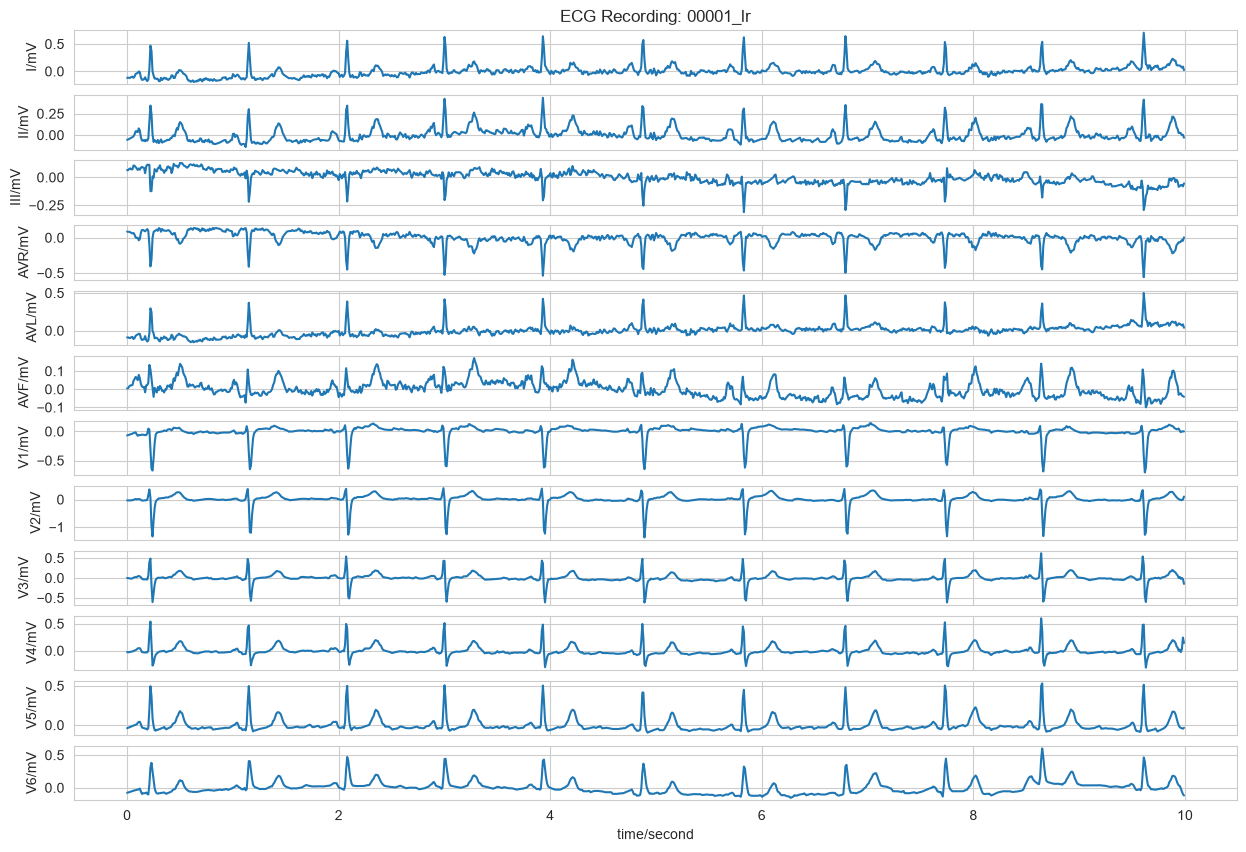

In [46]:

# ============================================================
# 3. VISUALIZE THE FIRST ECG RECORDING
# ============================================================

wfdb.plot_wfdb(
    record=record,
    title="ECG Recording: 00001_lr",
    figsize=(15, 10),
    plot_sym=True
)

plt.show()


Sampling Frequency: 100 Hz
Number of Samples: 1000
Number of Leads: 12
Recording Duration: 10.0 seconds


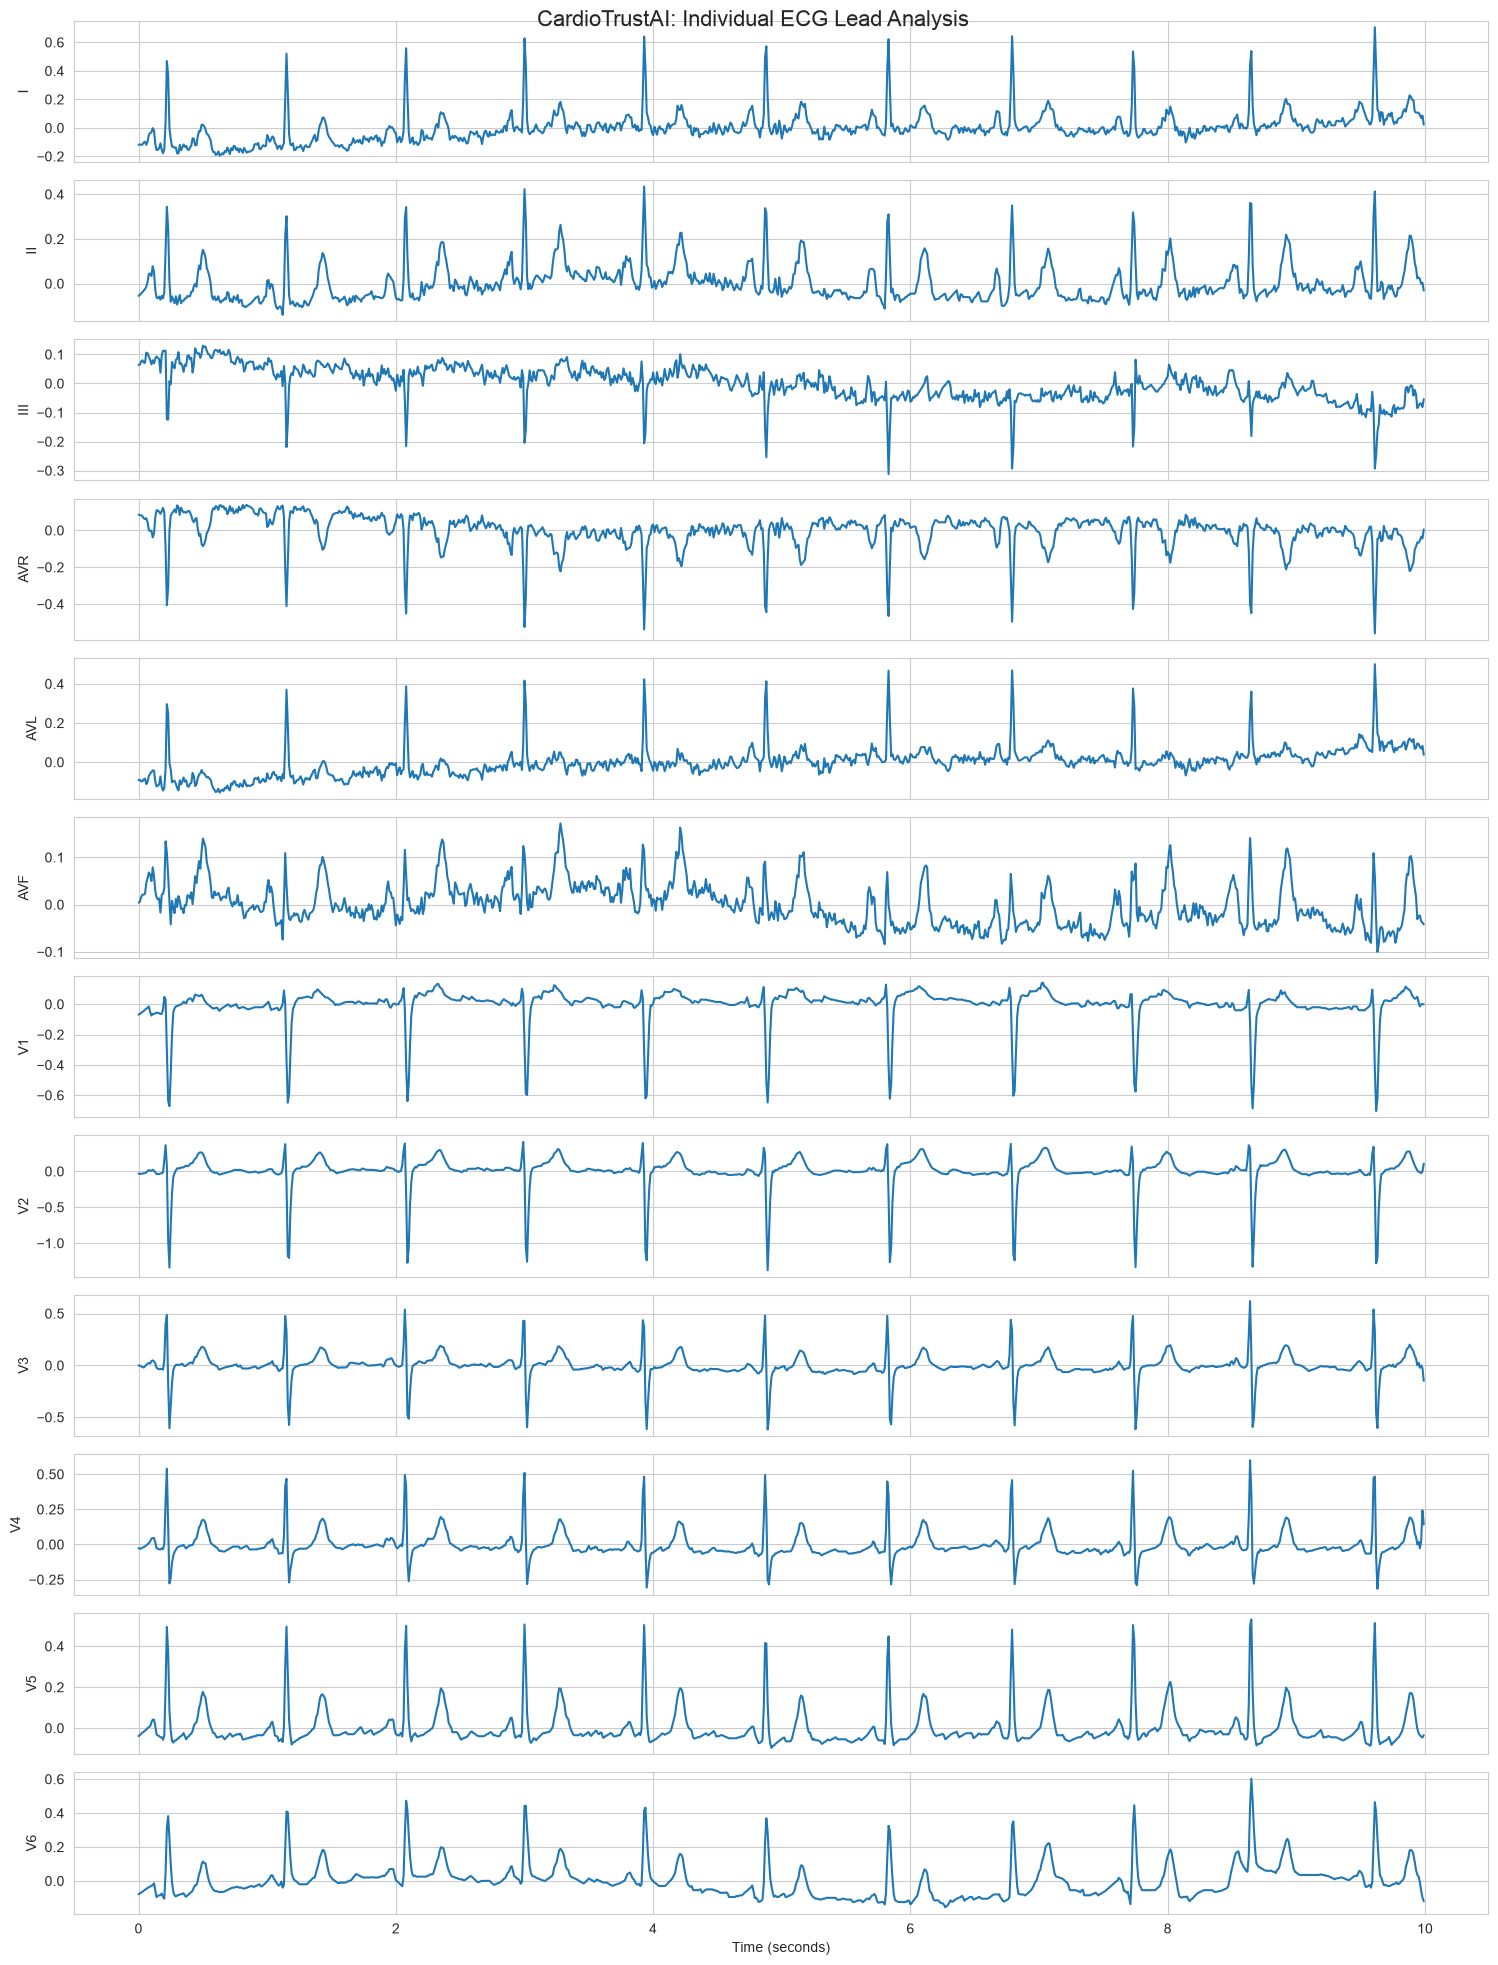


ECG Lead Statistics:


,Lead,Mean,Standard Deviation,Minimum,Maximum,Median,Missing Values,Infinite Values
0,I,0.001508,0.109022,-0.195,0.706,-0.0090,0,0
1,II,0.000723,0.083223,-0.140,0.435,-0.0235,0,0
2,III,-0.000778,0.058730,-0.312,0.130,0.0020,0,0
3,AVR,-0.001113,0.092383,-0.559,0.138,0.0160,0,0
4,AVL,0.001211,0.076968,-0.155,0.500,0.0000,0,0
5,AVF,0.000007,0.046863,-0.100,0.172,-0.0075,0,0
6,V1,-0.001709,0.113117,-0.704,0.142,0.0150,0,0
7,V2,0.006999,0.214230,-1.377,0.410,0.0110,0,0
8,V3,-0.001777,0.117834,-0.618,0.620,-0.0100,0,0
9,V4,-0.004089,0.095415,-0.315,0.599,-0.0250,0,0



Overall ECG Signal Validation:
ECG Signal Shape: (1000, 12)
Total Missing Values: 0
Total Infinite Values: 0
All Values Finite: True

Overall Signal Amplitude:
Minimum Amplitude: -1.377
Maximum Amplitude: 0.706
Mean Amplitude: 0.00010474999999999864
Standard Deviation: 0.1076345473230482

ECG WAVEFORM ANALYSIS COMPLETED
Recording: 00001_lr
Sampling Rate: 100 Hz
Duration: 10.0 seconds
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Signal Shape: (1000, 12)


In [47]:

# ============================================================
# CARDIOTRUSTAI - ECG WAVEFORM ANALYSIS
# ============================================================

# 4. CREATE ECG TIME AXIS

sampling_frequency = record.fs
num_samples = ecg_signal.shape[0]
lead_names = record.sig_name

time_axis = np.arange(num_samples) / sampling_frequency

print("Sampling Frequency:", sampling_frequency, "Hz")
print("Number of Samples:", num_samples)
print("Number of Leads:", len(lead_names))
print("Recording Duration:",
      time_axis[-1] + 1 / sampling_frequency, "seconds")


# 5. PLOT ALL 12 ECG LEADS

fig, axes = plt.subplots(
    nrows=len(lead_names),
    ncols=1,
    figsize=(15, 20),
    sharex=True
)

for i, lead in enumerate(lead_names):

    axes[i].plot(time_axis, ecg_signal[:, i])

    axes[i].set_ylabel(lead)
    axes[i].grid(True)

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "CardioTrustAI: Individual ECG Lead Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()


# 6. CALCULATE SIGNAL STATISTICS FOR EACH LEAD

lead_statistics = []

for i, lead in enumerate(lead_names):

    signal = ecg_signal[:, i]

    lead_statistics.append({
        "Lead": lead,
        "Mean": np.mean(signal),
        "Standard Deviation": np.std(signal),
        "Minimum": np.min(signal),
        "Maximum": np.max(signal),
        "Median": np.median(signal),
        "Missing Values": np.isnan(signal).sum(),
        "Infinite Values": np.isinf(signal).sum()
    })

df_lead_statistics = pd.DataFrame(lead_statistics)

print("\nECG Lead Statistics:")
display(df_lead_statistics)


# 7. OVERALL ECG SIGNAL VALIDATION

print("\nOverall ECG Signal Validation:")

print("ECG Signal Shape:", ecg_signal.shape)

print("Total Missing Values:",
      np.isnan(ecg_signal).sum())

print("Total Infinite Values:",
      np.isinf(ecg_signal).sum())

print("All Values Finite:",
      np.isfinite(ecg_signal).all())


# 8. CHECK SIGNAL AMPLITUDE RANGE

print("\nOverall Signal Amplitude:")

print("Minimum Amplitude:", np.min(ecg_signal))
print("Maximum Amplitude:", np.max(ecg_signal))
print("Mean Amplitude:", np.mean(ecg_signal))
print("Standard Deviation:", np.std(ecg_signal))


# 9. FINAL SUMMARY

print("\nECG WAVEFORM ANALYSIS COMPLETED")

print("Recording:", record.record_name)
print("Sampling Rate:", sampling_frequency, "Hz")
print("Duration:", round(time_axis[-1] + 1 / sampling_frequency, 2), "seconds")
print("Leads:", lead_names)
print("Signal Shape:", ecg_signal.shape)


ECG Signal Units:
['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']

Signal Gain:
[1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0]

ECG Signal Quality Measurements:


,Lead,Minimum,Maximum,Peak-to-Peak Amplitude,Standard Deviation
0,I,-0.195,0.706,0.901,0.109022
1,II,-0.140,0.435,0.575,0.083223
2,III,-0.312,0.130,0.442,0.058730
3,AVR,-0.559,0.138,0.697,0.092383
4,AVL,-0.155,0.500,0.655,0.076968
5,AVF,-0.100,0.172,0.272,0.046863
6,V1,-0.704,0.142,0.846,0.113117
7,V2,-1.377,0.410,1.787,0.214230
8,V3,-0.618,0.620,1.238,0.117834
9,V4,-0.315,0.599,0.914,0.095415


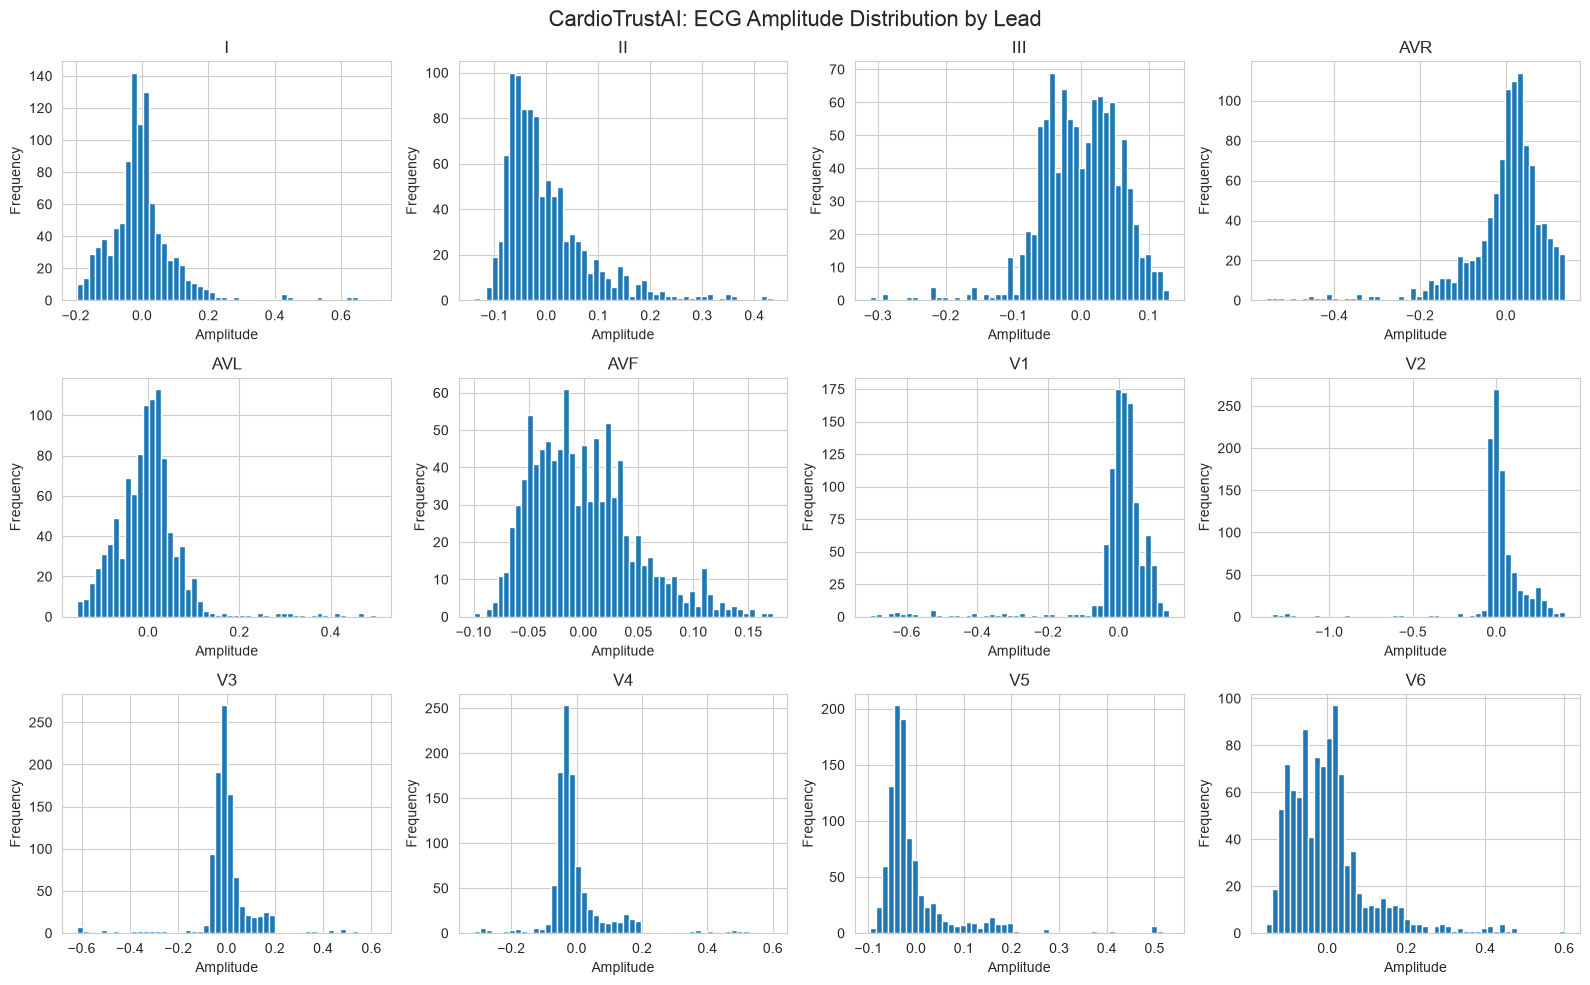


Extreme Amplitude Inspection:
I Extreme Samples: 24 out of 1000
II Extreme Samples: 15 out of 1000
III Extreme Samples: 3 out of 1000
AVR Extreme Samples: 22 out of 1000
AVL Extreme Samples: 20 out of 1000
AVF Extreme Samples: 0 out of 1000
V1 Extreme Samples: 46 out of 1000
V2 Extreme Samples: 48 out of 1000
V3 Extreme Samples: 57 out of 1000
V4 Extreme Samples: 94 out of 1000
V5 Extreme Samples: 80 out of 1000
V6 Extreme Samples: 17 out of 1000

SIGNAL QUALITY ASSESSMENT COMPLETED
Recording: 00001_lr
Sampling Frequency: 100 Hz
Signal Shape: (1000, 12)
All Values Finite: True


,Lead,Minimum,Maximum,Peak-to-Peak Amplitude,Standard Deviation
0,I,-0.195,0.706,0.901,0.109022
1,II,-0.140,0.435,0.575,0.083223
2,III,-0.312,0.130,0.442,0.058730
3,AVR,-0.559,0.138,0.697,0.092383
4,AVL,-0.155,0.500,0.655,0.076968
5,AVF,-0.100,0.172,0.272,0.046863
6,V1,-0.704,0.142,0.846,0.113117
7,V2,-1.377,0.410,1.787,0.214230
8,V3,-0.618,0.620,1.238,0.117834
9,V4,-0.315,0.599,0.914,0.095415


In [48]:

# ============================================================
# CARDIOTRUSTAI - ECG SIGNAL QUALITY ASSESSMENT
# ============================================================

# 10. CHECK ECG SIGNAL UNITS

print("ECG Signal Units:")
print(record.units)

print("\nSignal Gain:")
print(record.adc_gain)


# 11. CALCULATE AMPLITUDE RANGE FOR EACH LEAD

signal_quality_results = []

for i, lead in enumerate(lead_names):

    signal = ecg_signal[:, i]

    signal_min = np.min(signal)
    signal_max = np.max(signal)

    peak_to_peak = signal_max - signal_min
    standard_deviation = np.std(signal)

    signal_quality_results.append({
        "Lead": lead,
        "Minimum": signal_min,
        "Maximum": signal_max,
        "Peak-to-Peak Amplitude": peak_to_peak,
        "Standard Deviation": standard_deviation
    })

df_signal_quality = pd.DataFrame(signal_quality_results)

print("\nECG Signal Quality Measurements:")
display(df_signal_quality)


# 12. VISUALIZE ECG SIGNAL DISTRIBUTION

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(16, 10)
)

for i, lead in enumerate(lead_names):

    row = i // 4
    col = i % 4

    axes[row, col].hist(
        ecg_signal[:, i],
        bins=50
    )

    axes[row, col].set_title(lead)
    axes[row, col].set_xlabel("Amplitude")
    axes[row, col].set_ylabel("Frequency")
    axes[row, col].grid(True)

plt.suptitle(
    "CardioTrustAI: ECG Amplitude Distribution by Lead",
    fontsize=16
)

plt.tight_layout()
plt.show()


# 13. CHECK FOR EXTREME AMPLITUDE VALUES

print("\nExtreme Amplitude Inspection:")

for i, lead in enumerate(lead_names):

    signal = ecg_signal[:, i]

    q1 = np.percentile(signal, 25)
    q3 = np.percentile(signal, 75)

    iqr = q3 - q1

    lower_bound = q1 - (3 * iqr)
    upper_bound = q3 + (3 * iqr)

    extreme_count = np.sum(
        (signal < lower_bound) |
        (signal > upper_bound)
    )

    print(
        lead,
        "Extreme Samples:",
        extreme_count,
        "out of",
        len(signal)
    )


# 14. FINAL SIGNAL QUALITY SUMMARY

print("\nSIGNAL QUALITY ASSESSMENT COMPLETED")

print("Recording:", record.record_name)
print("Sampling Frequency:", sampling_frequency, "Hz")
print("Signal Shape:", ecg_signal.shape)
print("All Values Finite:", np.isfinite(ecg_signal).all())

display(df_signal_quality)


Sampling Frequency: 100 Hz
Nyquist Frequency: 50.0 Hz

Frequency Analysis Results:


,Lead,Baseline Band Power,ECG Band Power,High Frequency Power,Total Measured Band Power
0,I,0.000450,0.008991,0.000028,0.009469
1,II,0.001118,0.005633,0.000012,0.006762
2,III,0.000972,0.001542,0.000022,0.002536
3,AVR,0.000545,0.006919,0.000014,0.007479
4,AVL,0.000433,0.003850,0.000022,0.004305
5,AVF,0.000921,0.001330,0.000010,0.002260
6,V1,0.000122,0.011825,0.000002,0.011949
7,V2,0.000207,0.044079,0.000025,0.044312
8,V3,0.000369,0.012707,0.000009,0.013086
9,V4,0.000210,0.008153,0.000006,0.008369


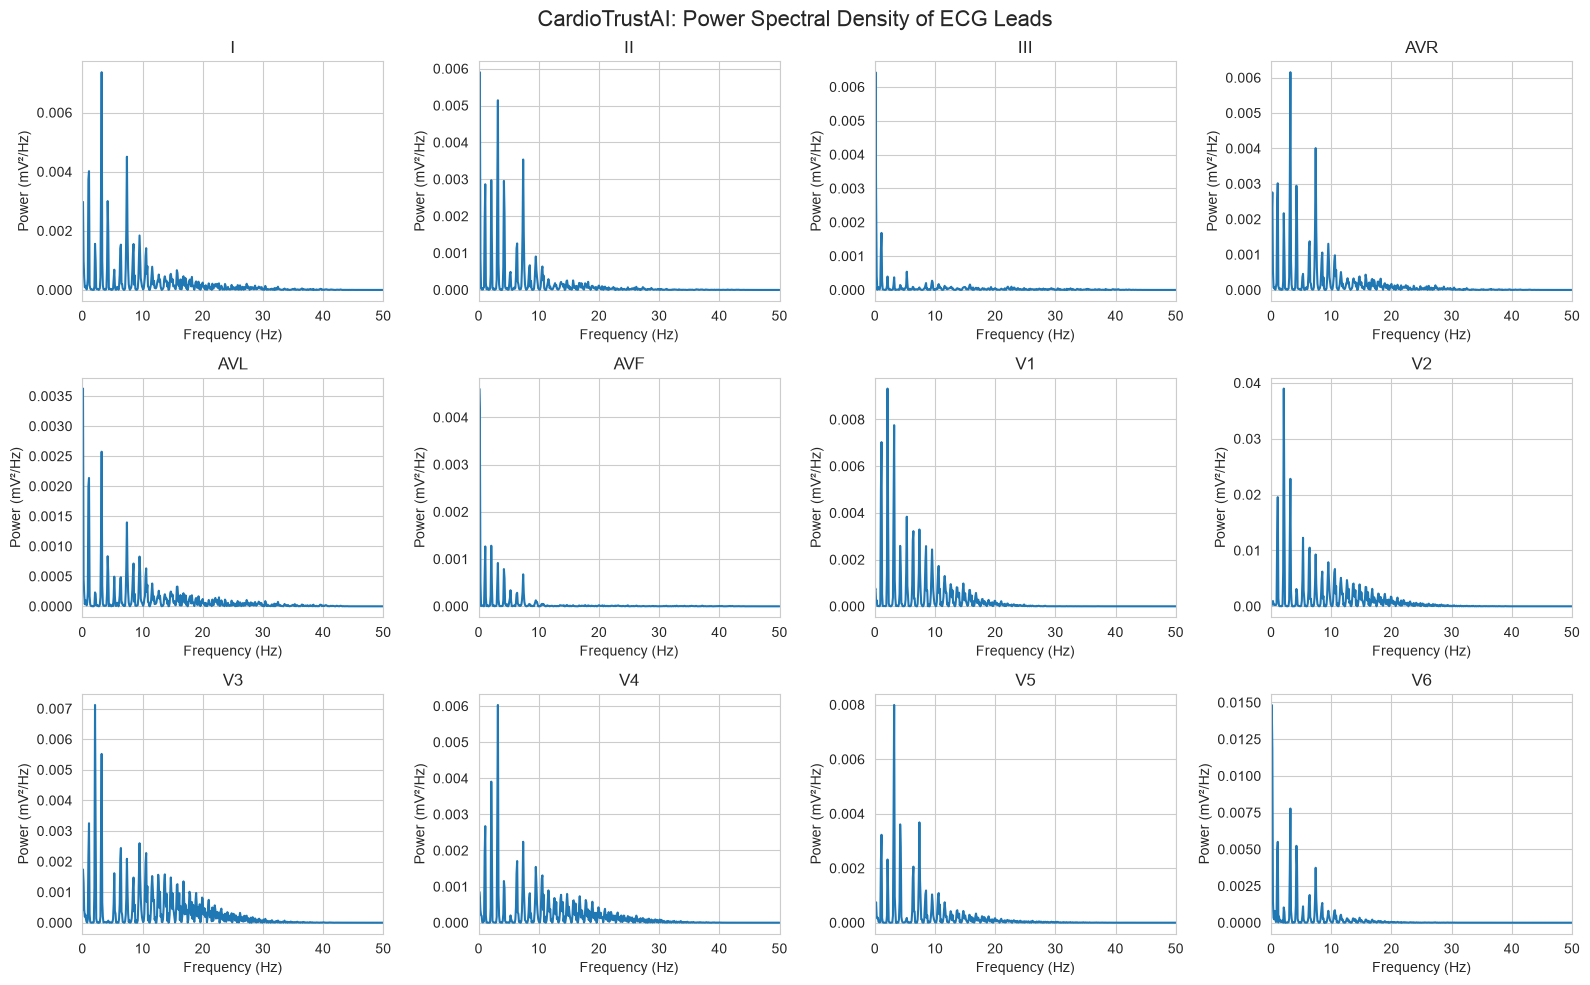

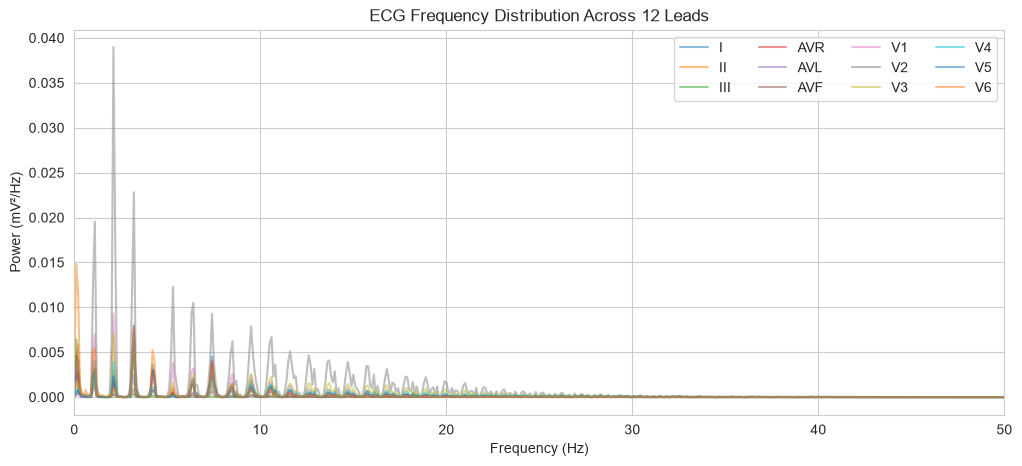


ECG FREQUENCY ANALYSIS COMPLETED
Recording: 00001_lr
Sampling Frequency: 100 Hz
Nyquist Frequency: 50.0 Hz

Frequency Bands:
Baseline Wander Investigation: (0.1, 0.5) Hz
ECG Frequency Content: (0.5, 40.0) Hz
High-Frequency Investigation: (40.0, 49.0) Hz

Frequency Analysis Shape: (12, 5)


,Lead,Baseline Band Power,ECG Band Power,High Frequency Power,Total Measured Band Power
0,I,0.000450,0.008991,0.000028,0.009469
1,II,0.001118,0.005633,0.000012,0.006762
2,III,0.000972,0.001542,0.000022,0.002536
3,AVR,0.000545,0.006919,0.000014,0.007479
4,AVL,0.000433,0.003850,0.000022,0.004305
5,AVF,0.000921,0.001330,0.000010,0.002260
6,V1,0.000122,0.011825,0.000002,0.011949
7,V2,0.000207,0.044079,0.000025,0.044312
8,V3,0.000369,0.012707,0.000009,0.013086
9,V4,0.000210,0.008153,0.000006,0.008369


In [49]:

# ============================================================
# CARDIOTRUSTAI - ECG FREQUENCY AND NOISE ANALYSIS
# ============================================================

from scipy.signal import welch

# 15. DEFINE FREQUENCY RANGES

nyquist_frequency = sampling_frequency / 2

print("Sampling Frequency:", sampling_frequency, "Hz")
print("Nyquist Frequency:", nyquist_frequency, "Hz")

baseline_band = (0.1, 0.5)
ecg_band = (0.5, 40.0)
high_frequency_band = (40.0, 49.0)


# 16. CALCULATE POWER SPECTRAL DENSITY FOR EACH LEAD

frequency_results = []
psd_results = {}

for i, lead in enumerate(lead_names):

    signal = ecg_signal[:, i]

    frequencies, psd = welch(
        signal,
        fs=sampling_frequency,
        nperseg=len(signal),
        detrend="constant"
    )

    psd_results[lead] = (frequencies, psd)

    frequency_resolution = frequencies[1] - frequencies[0]

    baseline_power = np.sum(
        psd[
            (frequencies >= baseline_band[0]) &
            (frequencies < baseline_band[1])
        ]
    ) * frequency_resolution

    ecg_power = np.sum(
        psd[
            (frequencies >= ecg_band[0]) &
            (frequencies < ecg_band[1])
        ]
    ) * frequency_resolution

    high_frequency_power = np.sum(
        psd[
            (frequencies >= high_frequency_band[0]) &
            (frequencies < high_frequency_band[1])
        ]
    ) * frequency_resolution

    total_power = baseline_power + ecg_power + high_frequency_power

    frequency_results.append({
        "Lead": lead,
        "Baseline Band Power": baseline_power,
        "ECG Band Power": ecg_power,
        "High Frequency Power": high_frequency_power,
        "Total Measured Band Power": total_power
    })


df_frequency_analysis = pd.DataFrame(frequency_results)

print("\nFrequency Analysis Results:")
display(df_frequency_analysis)


# 17. PLOT POWER SPECTRAL DENSITY FOR ALL 12 LEADS

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(16, 10)
)

for i, lead in enumerate(lead_names):

    row = i // 4
    col = i % 4

    frequencies, psd = psd_results[lead]

    axes[row, col].plot(frequencies, psd)

    axes[row, col].set_title(lead)
    axes[row, col].set_xlabel("Frequency (Hz)")
    axes[row, col].set_ylabel("Power (mV²/Hz)")
    axes[row, col].set_xlim(0, nyquist_frequency)
    axes[row, col].grid(True)

plt.suptitle(
    "CardioTrustAI: Power Spectral Density of ECG Leads",
    fontsize=16
)

plt.tight_layout()
plt.show()


# 18. PLOT AVERAGE FREQUENCY DISTRIBUTION

plt.figure(figsize=(12, 5))

for lead in lead_names:

    frequencies, psd = psd_results[lead]

    plt.plot(
        frequencies,
        psd,
        alpha=0.5,
        label=lead
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (mV²/Hz)")
plt.title("ECG Frequency Distribution Across 12 Leads")
plt.xlim(0, nyquist_frequency)
plt.grid(True)
plt.legend(ncol=4)
plt.show()


# 19. FINAL FREQUENCY ANALYSIS SUMMARY

print("\nECG FREQUENCY ANALYSIS COMPLETED")

print("Recording:", record.record_name)
print("Sampling Frequency:", sampling_frequency, "Hz")
print("Nyquist Frequency:", nyquist_frequency, "Hz")

print("\nFrequency Bands:")
print("Baseline Wander Investigation:", baseline_band, "Hz")
print("ECG Frequency Content:", ecg_band, "Hz")
print("High-Frequency Investigation:", high_frequency_band, "Hz")

print("\nFrequency Analysis Shape:",
      df_frequency_analysis.shape)

display(df_frequency_analysis)
